In [1]:
from pathlib import Path
PROJECT = Path(r'D:\tcc_ibov')
DIRS = {k: PROJECT / v for k, v in {
    'raw': 'data/raw', 'processed': 'data/processed',
    'models': 'models', 'reports': 'reports', 'utils': 'utils',
}.items()}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)

# tcc_utils.py (com make_target e walk_forward_splits) e gravado uma unica vez
# pelo notebook 00_setup -- aqui so importa.
import sys; sys.path.insert(0, str(DIRS['utils']))
import importlib, tcc_utils; importlib.reload(tcc_utils)
from tcc_utils import make_target, walk_forward_splits

import pandas as pd, numpy as np
print("Setup OK -- make_target, walk_forward_splits carregados.")


Setup OK -- make_target, walk_forward_splits carregados.


In [2]:
precos = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
estudo = precos.loc['2019-01-01':'2024-12-31'].copy()

estudo['y'] = make_target(estudo)
n_sem_alvo = estudo['y'].isna().sum()
print(f"Sem alvo (último dia, esperado 1): {n_sem_alvo}")
estudo = estudo.dropna(subset=['y'])   # descarta 31/12/2024
print(f"Amostras com alvo: {len(estudo)}")

# Inspeciona a geometria dos folds ANTES de treinar nada — é aqui que
# vazamento temporal se esconde. Cada teste deve começar exatamente onde
# o treino termina, e as datas de teste devem ser estritamente futuras.
splits = walk_forward_splits(estudo.index, n_splits=5, min_train=252, expanding=True)
print(f"\n{len(splits)} folds (treino expansível):")
for k, (tr, te) in enumerate(splits, 1):
    print(f"  fold {k}: treino [{estudo.index[tr[0]].date()} -> "
          f"{estudo.index[tr[-1]].date()}] ({len(tr)}) | "
          f"teste [{estudo.index[te[0]].date()} -> "
          f"{estudo.index[te[-1]].date()}] ({len(te)})")

# Verificação dura anti-vazamento: nenhum índice de teste pode aparecer no treino
for k, (tr, te) in enumerate(splits, 1):
    assert set(tr).isdisjoint(set(te)), f"VAZAMENTO no fold {k}"
    assert te[0] == tr[-1] + 1, f"gap/overlap no fold {k}"
print("\nAnti-vazamento OK: treino e teste disjuntos e contíguos.")

Sem alvo (último dia, esperado 1): 1
Amostras com alvo: 1492

5 folds (treino expansível):
  fold 1: treino [2019-01-02 -> 2020-01-07] (252) | teste [2020-01-08 -> 2020-11-03] (206)
  fold 2: treino [2019-01-02 -> 2020-11-03] (458) | teste [2020-11-04 -> 2021-09-02] (206)
  fold 3: treino [2019-01-02 -> 2021-09-02] (664) | teste [2021-09-03 -> 2022-07-04] (206)
  fold 4: treino [2019-01-02 -> 2022-07-04] (870) | teste [2022-07-05 -> 2023-05-02] (206)
  fold 5: treino [2019-01-02 -> 2023-05-02] (1076) | teste [2023-05-03 -> 2024-02-28] (206)

Anti-vazamento OK: treino e teste disjuntos e contíguos.


In [3]:
from sklearn.metrics import (mean_absolute_error, f1_score,
                             matthews_corrcoef, brier_score_loss)

def directional_accuracy(y_true, y_pred):
    return (np.sign(y_true) == np.sign(y_pred)).mean()

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

y = estudo['y'].values
resultados = []

for k, (tr, te) in enumerate(splits, 1):
    y_tr, y_te = y[tr], y[te]

    # --- Random Walk para REGRESSÃO: prevê 0 (retorno esperado do passeio) ---
    pred_zero = np.zeros_like(y_te)

    # --- Random Walk DIRECIONAL: persistência (direção de hoje p/ amanhã) ---
    # pred de direção do dia t = sinal do retorno do dia t (log_ret atual,
    # NÃO o alvo). Usamos o retorno realizado até t, que é conhecido em t.
    ret_hoje = estudo['log_ret'].values
    pred_persist = np.sign(ret_hoje[te])   # +1/-1/0

    # --- Brier climatológico: P(alta) = freq. de alta NO TREINO (sem vazar) ---
    p_alta_treino = (y_tr > 0).mean()
    y_te_bin = (y_te > 0).astype(int)
    brier_clim = brier_score_loss(y_te_bin, np.full(len(y_te), p_alta_treino))

    resultados.append({
        'fold': k,
        'MAE_rw0': mean_absolute_error(y_te, pred_zero),
        'RMSE_rw0': rmse(y_te, pred_zero),
        'DA_persist': directional_accuracy(y_te, pred_persist),
        'F1_persist': f1_score(y_te_bin, (pred_persist > 0).astype(int), zero_division=0),
        'MCC_persist': matthews_corrcoef(y_te_bin, (pred_persist > 0).astype(int)),
        'Brier_clim': brier_clim,
        'p_alta_treino': p_alta_treino,
    })

res = pd.DataFrame(resultados).set_index('fold')
print(res.round(4).to_string())
print("\nMédia across folds:")
print(res.mean().round(4).to_string())

res.to_parquet(DIRS['reports'] / 'baseline_random_walk.parquet')
print("\nSalvo: baseline_random_walk.parquet")

      MAE_rw0  RMSE_rw0  DA_persist  F1_persist  MCC_persist  Brier_clim  p_alta_treino
fold                                                                                   
1      0.0195    0.0308      0.4029      0.4000      -0.1942      0.2516         0.5397
2      0.0097    0.0125      0.4563      0.5130      -0.1023      0.2479         0.5218
3      0.0103    0.0130      0.5194      0.5025       0.0377      0.2524         0.5331
4      0.0109    0.0139      0.5243      0.5377       0.0477      0.2498         0.5207
5      0.0076    0.0095      0.5243      0.5505       0.0453      0.2492         0.5195

Média across folds:
MAE_rw0          0.0116
RMSE_rw0         0.0159
DA_persist       0.4854
F1_persist       0.5008
MCC_persist     -0.0331
Brier_clim       0.2502
p_alta_treino    0.5270

Salvo: baseline_random_walk.parquet


Série de retornos: 1492 pregões



ADF: estatística=-11.86 | p-valor=7.00e-22
  -> estacionária (d=0 correto)

Ljung-Box (H0: ruído branco):
     lb_stat  lb_pvalue
5    57.2129        0.0
10  113.9048        0.0
20  133.0283        0.0

Ljung-Box em r² (H0: sem clustering de volatilidade):
      lb_stat  lb_pvalue
5   1749.9952        0.0
10  2104.9287        0.0
20  2249.9730        0.0


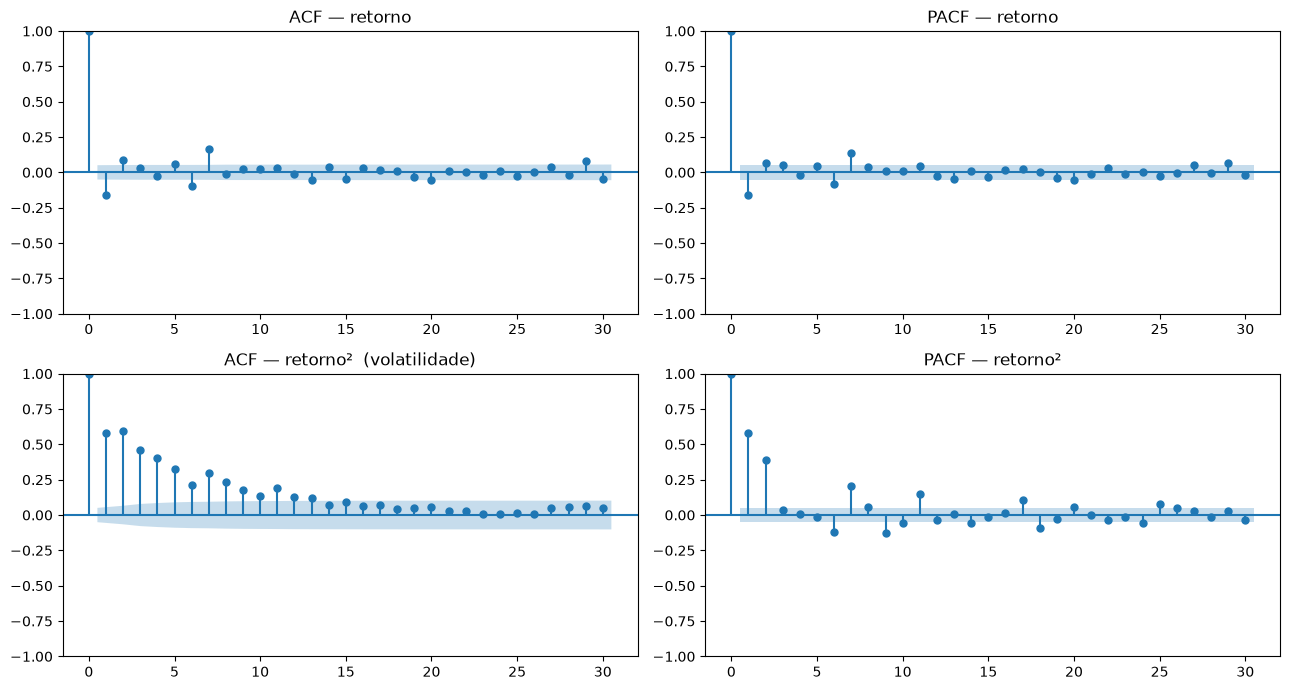

In [4]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller

# Usamos o log_ret do PERÍODO DE ESTUDO (a série que o ARIMA vai modelar).
# Não é o alvo (D+1); é a própria série de retornos, cuja autocorrelação
# determina se há QUALQUER estrutura linear a explorar.
r = estudo['log_ret'].dropna()
print(f"Série de retornos: {len(r)} pregões\n")

# --- ADF: confirma estacionariedade (pré-requisito do ARIMA com d=0) ---
adf_stat, adf_p, *_ = adfuller(r, autolag='AIC')
print(f"ADF: estatística={adf_stat:.2f} | p-valor={adf_p:.2e}")
print(f"  -> {'estacionária (d=0 correto)' if adf_p < 0.05 else 'NÃO estacionária'}\n")

# --- Ljung-Box: existe autocorrelação significativa até lag 10/20? ---
# H0 = sem autocorrelação (ruído branco). p<0.05 -> há estrutura a modelar.
lb = acorr_ljungbox(r, lags=[5, 10, 20], return_df=True)
print("Ljung-Box (H0: ruído branco):")
print(lb.round(4).to_string())
print()

# --- Mesmo teste no retorno AO QUADRADO: detecta clustering de volatilidade ---
# Se r é ruído branco mas r² não é, a estrutura está na VARIÂNCIA (ARCH/GARCH),
# não na média -> ARIMA não captura, mas é um achado importante p/ o TCC.
lb2 = acorr_ljungbox(r**2, lags=[5, 10, 20], return_df=True)
print("Ljung-Box em r² (H0: sem clustering de volatilidade):")
print(lb2.round(4).to_string())

# --- Figura ACF/PACF (candidata a figura do TCC) ---
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(r, lags=30, ax=axes[0,0]);  axes[0,0].set_title('ACF — retorno')
plot_pacf(r, lags=30, ax=axes[0,1], method='ywm'); axes[0,1].set_title('PACF — retorno')
plot_acf(r**2, lags=30, ax=axes[1,0]); axes[1,0].set_title('ACF — retorno²  (volatilidade)')
plot_pacf(r**2, lags=30, ax=axes[1,1], method='ywm'); axes[1,1].set_title('PACF — retorno²')
plt.tight_layout()
fig.savefig(DIRS['reports'] / 'acf_pacf_retorno.png', dpi=130)
plt.show()

In [5]:
# pmdarima costuma ter conflito de versão de numpy no Colab. Instalamos e
# TESTAMOS o import numa célula isolada, porque se quebrar, quebra feio
# (às vezes exige restart de runtime).

import pmdarima as pm
import numpy as np
print(f"pmdarima {pm.__version__} | numpy {np.__version__}")

pmdarima 2.1.1 | numpy 2.4.6


In [6]:
import warnings, time
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, f1_score, matthews_corrcoef, brier_score_loss

feat_txt = pd.read_parquet(DIRS['processed'] / 'features_texto_bertimbau.parquet')
# Alinha features textuais ao índice do estudo (com alvo). Mesmas datas.
feat_txt = feat_txt.reindex(estudo.index)

serie = estudo['log_ret'].values
y = estudo['y'].values

# Exógenas DEFASADAS: feature do dia t -> prevê retorno do dia t+1.
# Construímos exog_para_alvo[t] = features[t] (features de hoje p/ prever amanhã).
EXOG_COLS = ['n_noticias', 'emb_dispersao']
exog_raw = feat_txt[EXOG_COLS].values      # alinhado a estudo.index (dia t)

def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))
def da(a, b): return (np.sign(a) == np.sign(b)).mean()

def pesaran_timmermann(y_true, y_pred):
    """PT test: a acurácia direcional é melhor que o acaso?
    Retorna (estatística, p-valor unilateral). z>1.645 -> p<0.05."""
    from scipy.stats import norm
    n = len(y_true)
    dy = (y_true > 0).astype(int); dp = (y_pred > 0).astype(int)
    py, pp = dy.mean(), dp.mean()
    p_hat = (dy == dp).mean()
    p_star = py*pp + (1-py)*(1-pp)
    var_hat = p_star*(1-p_star)/n
    var_star = (((2*py-1)**2)*pp*(1-pp)/n
                + ((2*pp-1)**2)*py*(1-py)/n
                + 4*py*pp*(1-py)*(1-pp)/n**2)
    denom = np.sqrt(max(var_hat - var_star, 1e-12))
    z = (p_hat - p_star)/denom
    return z, 1 - norm.cdf(z)

def roda_modelo(usar_exog):
    resultados, todas_preds = [], {}
    for k, (tr, te) in enumerate(splits, 1):
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            import pmdarima as pm
            auto = pm.auto_arima(serie[tr], d=0, start_p=0, max_p=5, start_q=0, max_q=5,
                                 seasonal=False, stepwise=True, information_criterion='aic',
                                 suppress_warnings=True, error_action='ignore')
        order = auto.order

        # z-score das exógenas no treino do fold (sem vazar)
        if usar_exog:
            mu = exog_raw[tr].mean(axis=0); sd = exog_raw[tr].std(axis=0) + 1e-9
            exog_z = (exog_raw - mu) / sd
            # exog DEFASADA p/ o ajuste: exog_lag[s] = exog_z[s-1], de modo que
            # o modelo aprenda y_s ~ x_{s-1} -- a MESMA relação usada no
            # forecast (prever y_{t+1} com x_t). A 1a linha não tem D-1 e
            # duplica a própria (1 obs de treino, efeito desprezível).
            exog_lag = np.empty_like(exog_z)
            exog_lag[1:] = exog_z[:-1]
            exog_lag[0] = exog_z[0]

        preds = np.empty(len(te))
        for j, t in enumerate(te):
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                if usar_exog:
                    # ajuste com exog defasada (y_s ~ x_{s-1}); o forecast de
                    # serie[t+1] usa exog_z[t] (= exog_lag[t+1]) -- alinhamento
                    # consistente entre estimação e previsão. (A versão
                    # anterior ajustava contemporâneo y_s ~ x_s e previa com
                    # x_t: coeficiente estimado numa relação, aplicado noutra.)
                    m = ARIMA(serie[:t+1], exog=exog_lag[:t+1], order=order).fit()
                    preds[j] = m.forecast(steps=1, exog=exog_z[t:t+1])[0]
                else:
                    m = ARIMA(serie[:t+1], order=order).fit()
                    preds[j] = m.forecast(steps=1)[0]

        y_te = y[te]; y_bin = (y_te > 0).astype(int); p_alta = (y[tr] > 0).mean()
        z_pt, p_pt = pesaran_timmermann(y_te, preds)
        todas_preds[k] = preds
        resultados.append({
            'fold': k, 'ordem': str(order),
            'MAE': mean_absolute_error(y_te, preds), 'RMSE': rmse(y_te, preds),
            'DA': da(y_te, preds),
            'F1': f1_score(y_bin, (preds > 0).astype(int), zero_division=0),
            'MCC': matthews_corrcoef(y_bin, (preds > 0).astype(int)),
            'PT_z': z_pt, 'PT_p': p_pt,
        })
        print(f"  fold {k}: {order} | DA {da(y_te,preds):.3f} | "
              f"PT_p {p_pt:.3f} | {time.time()-t0:.0f}s")
    return pd.DataFrame(resultados).set_index('fold'), todas_preds

print("=== ARIMA puro ===")
res_arima, preds_arima = roda_modelo(usar_exog=False)
print("\n=== ARIMAX (texto: n_noticias + emb_dispersao) ===")
res_arimax, preds_arimax = roda_modelo(usar_exog=True)

# Salva previsões p/ Diebold-Mariano futuro
np.savez(DIRS['reports'] / 'preds_arima.npz',
         **{f'arima_f{k}': v for k, v in preds_arima.items()},
         **{f'arimax_f{k}': v for k, v in preds_arimax.items()})

print("\n--- ARIMA média ---")
print(res_arima.drop(columns='ordem').mean().round(4).to_string())
print("\n--- ARIMAX média ---")
print(res_arimax.drop(columns='ordem').mean().round(4).to_string())

res_arima.to_parquet(DIRS['reports'] / 'baseline_arima.parquet')
res_arimax.to_parquet(DIRS['reports'] / 'baseline_arimax.parquet')
print("\nSalvos.")

=== ARIMA puro ===


  fold 1: (0, 0, 0) | DA 0.490 | PT_p 0.623 | 17s


  fold 2: (3, 0, 0) | DA 0.549 | PT_p 0.145 | 29s


  fold 3: (2, 0, 1) | DA 0.519 | PT_p 0.267 | 123s


  fold 4: (3, 0, 2) | DA 0.519 | PT_p 0.299 | 187s


  fold 5: (3, 0, 0) | DA 0.534 | PT_p 0.187 | 69s

=== ARIMAX (texto: n_noticias + emb_dispersao) ===


  fold 1: (0, 0, 0) | DA 0.490 | PT_p 0.628 | 24s


  fold 2: (3, 0, 0) | DA 0.539 | PT_p 0.382 | 47s


  fold 3: (2, 0, 1) | DA 0.476 | PT_p 0.758 | 159s


  fold 4: (3, 0, 2) | DA 0.519 | PT_p 0.301 | 223s


  fold 5: (3, 0, 0) | DA 0.529 | PT_p 0.260 | 51s

--- ARIMA média ---
MAE     0.0120
RMSE    0.0166
DA      0.5223
F1      0.5699
MCC     0.0387
PT_z    0.5561
PT_p    0.3043

--- ARIMAX média ---
MAE     0.0124
RMSE    0.0181
DA      0.5107
F1      0.5703
MCC     0.0061
PT_z    0.0875
PT_p    0.4659

Salvos.


In [7]:
# Partimos da série COMPLETA com buffer (não só o estudo), para as janelas
# longas terem histórico em jan/2019. Recortamos p/ o estudo DEPOIS.
precos_full = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
df = precos_full.copy()
r = df['log_ret']

feat = pd.DataFrame(index=df.index)

# --- Retornos defasados (o AR(3) do ARIMA sugere sinal nos primeiros lags) ---
for lag in [0, 1, 2, 3, 5, 10]:
    feat[f'ret_lag{lag}'] = r.shift(lag)   # lag0 = retorno de hoje (conhecido em t)

# --- Volatilidade realizada (captura o clustering de vol da figura ACF) ---
for w in [5, 10, 21]:
    feat[f'vol_{w}'] = r.rolling(w).std()

# --- Retorno acumulado em janelas (momento de curto/médio prazo) ---
for w in [5, 10, 21]:
    feat[f'mom_{w}'] = r.rolling(w).sum()

# --- Distância do preço à sua média móvel (mean-reversion / tendência) ---
for w in [10, 21]:
    ma = df['Close'].rolling(w).mean()
    feat[f'dist_ma{w}'] = (df['Close'] - ma) / ma

# --- Calendário (o lag-7 da figura sugere efeito semanal) ---
feat['dow'] = df.index.dayofweek          # 0=seg ... 4=sex
feat['month'] = df.index.month

# --- ALVO: log_ret de D+1 (o mesmo make_target, mesma regra) ---
feat['y'] = make_target(df)

# Recorte do estudo + limpeza. NaN só deve existir no buffer (janelas) e no
# último dia (alvo). Verificamos que nenhum NaN sobra DENTRO do estudo.
feat_estudo = feat.loc['2019-01-01':'2024-12-31'].copy()
print(f"Shape antes de dropna: {feat_estudo.shape}")
print(f"NaN por coluna (deve ser 0, exceto y na última linha):")
print(feat_estudo.isna().sum()[feat_estudo.isna().sum() > 0])

feat_estudo = feat_estudo.dropna()
print(f"\nShape após dropna: {feat_estudo.shape}")
print(f"Features: {[c for c in feat_estudo.columns if c != 'y']}")

feat_estudo.to_parquet(DIRS['processed'] / 'features_preco.parquet')
print(f"\nSalvo: features_preco.parquet")

Shape antes de dropna: (1493, 17)
NaN por coluna (deve ser 0, exceto y na última linha):
y    1
dtype: int64

Shape após dropna: (1492, 17)
Features: ['ret_lag0', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag5', 'ret_lag10', 'vol_5', 'vol_10', 'vol_21', 'mom_5', 'mom_10', 'mom_21', 'dist_ma10', 'dist_ma21', 'dow', 'month']

Salvo: features_preco.parquet


In [8]:
from xgboost import XGBRegressor, XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (mean_absolute_error, f1_score,
                             matthews_corrcoef, brier_score_loss)

feat = pd.read_parquet(DIRS['processed'] / 'features_preco.parquet')
X = feat.drop(columns='y').values
y = feat['y'].values
cols = feat.drop(columns='y').columns.tolist()

def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))
def da(a, b): return (np.sign(a) == np.sign(b)).mean()

# Hiperparâmetros fixos conservadores (dataset pequeno -> regularizar forte)
PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.02,
              subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
              min_child_weight=5, random_state=42, n_jobs=-1)

resultados, preds_reg_all, preds_prob_all = [], {}, {}
importancias = np.zeros(len(cols))

for k, (tr, te) in enumerate(splits, 1):
    # hold-out temporal interno p/ calibração: últimos 20% do treino
    n_cal = int(len(tr) * 0.2)
    tr_fit, tr_cal = tr[:-n_cal], tr[-n_cal:]

    # --- Regressor (MAE/RMSE) ---
    reg = XGBRegressor(**PARAMS).fit(X[tr], y[tr])
    p_reg = reg.predict(X[te])

    # --- Classificador de direção + calibração isotônica ---
    yb = (y > 0).astype(int)
    clf = XGBClassifier(**PARAMS, eval_metric='logloss').fit(X[tr_fit], yb[tr_fit])
    cal = CalibratedClassifierCV(FrozenEstimator(clf), method='isotonic').fit(X[tr_cal], yb[tr_cal])
    p_prob = cal.predict_proba(X[te])[:, 1]

    y_te = y[te]; yb_te = yb[te]; pred_dir = (p_prob > 0.5).astype(int)
    importancias += reg.feature_importances_
    preds_reg_all[k] = p_reg; preds_prob_all[k] = p_prob

    resultados.append({
        'fold': k,
        'MAE': mean_absolute_error(y_te, p_reg), 'RMSE': rmse(y_te, p_reg),
        'DA': da(y_te, p_reg),
        'F1': f1_score(yb_te, pred_dir, zero_division=0),
        'MCC': matthews_corrcoef(yb_te, pred_dir),
        'Brier': brier_score_loss(yb_te, p_prob),
    })

res_xgb = pd.DataFrame(resultados).set_index('fold')
print(res_xgb.round(4).to_string())
print("\nMédia:\n" + res_xgb.mean().round(4).to_string())

print("\nImportância das features (média entre folds):")
imp = pd.Series(importancias / len(splits), index=cols).sort_values(ascending=False)
print(imp.round(3).to_string())

np.savez(DIRS['reports'] / 'preds_xgboost.npz',
         **{f'reg_f{k}': v for k, v in preds_reg_all.items()},
         **{f'prob_f{k}': v for k, v in preds_prob_all.items()})
res_xgb.to_parquet(DIRS['reports'] / 'baseline_xgboost.parquet')
print("\nSalvos.")

         MAE    RMSE      DA      F1     MCC   Brier
fold                                                
1     0.0197  0.0310  0.4757  0.6733  0.1155  0.2519
2     0.0097  0.0125  0.5291  0.0800 -0.0265  0.3164
3     0.0106  0.0135  0.4903  0.5837 -0.0214  0.2692
4     0.0110  0.0140  0.5049  0.0000  0.0000  0.2511
5     0.0076  0.0095  0.5388  0.5340  0.1512  0.2468

Média:
MAE      0.0117
RMSE     0.0161
DA       0.5078
F1       0.3742
MCC      0.0438
Brier    0.2671

Importância das features (média entre folds):
dist_ma10    0.137
mom_10       0.090
dist_ma21    0.071
ret_lag5     0.067
ret_lag2     0.066
ret_lag0     0.064
mom_5        0.064
vol_5        0.062
vol_10       0.059
mom_21       0.058
ret_lag3     0.057
ret_lag1     0.048
vol_21       0.045
ret_lag10    0.042
dow          0.039
month        0.032

Salvos.


In [9]:
precos = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
v = precos['Volume']

# Teste 1: zeros e nulos (índice mal reportado costuma ter buracos)
print(f"Zeros: {(v==0).sum()} | Nulos: {v.isna().sum()} de {len(v)}")

# Teste 2: continuidade da ordem de grandeza por ano.
# Fonte que troca de definição no meio da série salta ordem de magnitude.
print("\nMediana de volume por ano:")
print(v.groupby(v.index.year).median().map(lambda x: f"{x:.3e}"))

# Teste 3: correlação volume-volatilidade (Karpoff 1987).
# Relação empírica robusta: dias voláteis têm mais volume. Se o volume for
# real, |retorno| e volume correlacionam POSITIVAMENTE. Ausência dessa
# correlação = sinal de que o "volume" não reflete negociação real.
r_abs = precos['log_ret'].abs()
corr = precos['log_ret'].abs().corr(v)
corr_log = r_abs.corr(np.log(v.replace(0, np.nan)))
print(f"\nCorrelação |retorno|-volume: {corr:.3f}")
print(f"Correlação |retorno|-log(volume): {corr_log:.3f}")
print("(Karpoff 1987: esperado POSITIVO e não-trivial se o volume é real)")

# Teste 4: autocorrelação do volume. Volume real tem forte persistência
# (clustering), como a volatilidade. Ruído aleatório não teria.
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(np.log(v.replace(0, np.nan)).dropna(), lags=[5], return_df=True)
print(f"\nLjung-Box log(volume) lag5 p-valor: {lb['lb_pvalue'].iloc[0]:.2e}")
print("(volume real é fortemente autocorrelacionado -> p deve ser ~0)")

Zeros: 0 | Nulos: 0 de 1615

Mediana de volume por ano:
Date
2018    3.974e+08
2019    4.746e+08
2020    9.523e+08
2021    9.446e+08
2022    1.269e+09
2023    1.172e+09
2024    9.289e+08
Name: Volume, dtype: str

Correlação |retorno|-volume: 0.181
Correlação |retorno|-log(volume): 0.157
(Karpoff 1987: esperado POSITIVO e não-trivial se o volume é real)

Ljung-Box log(volume) lag5 p-valor: 0.00e+00
(volume real é fortemente autocorrelacionado -> p deve ser ~0)


In [10]:
#@title Nível 3 — XGBoost (preço) · treino simétrico documentado + multi-semente
# CORREÇÕES vs. versão anterior:
#  (1) Assimetria DOCUMENTADA (opção b): o regressor treina em `tr` cheio pois
#      não requer calibração; o classificador treina em `tr_fit` e calibra em
#      `tr_cal` (hold-out TEMPORAL interno, sem tocar no teste). Regressão e
#      classificação são avaliações separadas do mesmo modelo — não se comparam
#      entre si, então usar conjuntos distintos é legítimo e mais eficiente
#      (não descarta 20% dos dados do regressor num dataset já pequeno).
#  (2) MULTI-SEMENTE: XGBoost é estocástico (subsample/colsample). Rodar 1 semente
#      confunde sinal com ruído de amostragem. Rodamos N=10 sementes e reportamos
#      média ± desvio POR FOLD, para separar efeito real de variância do método.
# Sem vazamento: nada aqui usa X[te]/y[te] no ajuste; calibração usa só tr_cal.

from xgboost import XGBRegressor, XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (mean_absolute_error, f1_score,
                             matthews_corrcoef, brier_score_loss)

feat = pd.read_parquet(DIRS['processed'] / 'features_preco.parquet')
X = feat.drop(columns='y').values
y = feat['y'].values
cols = feat.drop(columns='y').columns.tolist()

def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))
def da(a, b):   return (np.sign(a) == np.sign(b)).mean()

BASE_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.02,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
                   min_child_weight=5, n_jobs=-1)
SEEDS = list(range(10))          # 10 sementes
yb = (y > 0).astype(int)

# Estrutura: p/ cada (fold, seed) guardamos as métricas; depois agregamos
# sobre seeds dentro de cada fold. Previsões salvas = média sobre seeds
# (usadas depois no Diebold-Mariano).
registros = []
preds_reg_media = {}   # fold -> média das previsões de regressão sobre seeds
preds_prob_media = {}  # fold -> média das probabilidades sobre seeds
importancias = np.zeros(len(cols))

for k, (tr, te) in enumerate(splits, 1):
    n_cal = int(len(tr) * 0.2)
    tr_fit, tr_cal = tr[:-n_cal], tr[-n_cal:]

    reg_preds_seeds, prob_preds_seeds = [], []
    for s in SEEDS:
        P = dict(BASE_PARAMS, random_state=s)

        # Regressor: treina em tr cheio (não calibra) -> MAE/RMSE/DA
        reg = XGBRegressor(**P).fit(X[tr], y[tr])
        p_reg = reg.predict(X[te])
        reg_preds_seeds.append(p_reg)

        # Classificador: treina em tr_fit, calibra (isotônica) em tr_cal
        clf = XGBClassifier(**P, eval_metric='logloss').fit(X[tr_fit], yb[tr_fit])
        cal = CalibratedClassifierCV(FrozenEstimator(clf), method='isotonic').fit(
            X[tr_cal], yb[tr_cal])
        p_prob = cal.predict_proba(X[te])[:, 1]
        prob_preds_seeds.append(p_prob)

        importancias += reg.feature_importances_

        y_te = y[te]; yb_te = yb[te]; pred_dir = (p_prob > 0.5).astype(int)
        registros.append({
            'fold': k, 'seed': s,
            'MAE': mean_absolute_error(y_te, p_reg), 'RMSE': rmse(y_te, p_reg),
            'DA': da(y_te, p_reg),
            'F1': f1_score(yb_te, pred_dir, zero_division=0),
            'MCC': matthews_corrcoef(yb_te, pred_dir),
            'Brier': brier_score_loss(yb_te, p_prob),
        })

    # Previsão consolidada do fold = média sobre seeds (reduz variância p/ o DM)
    preds_reg_media[k]  = np.mean(reg_preds_seeds, axis=0)
    preds_prob_media[k] = np.mean(prob_preds_seeds, axis=0)

reg_df = pd.DataFrame(registros)

# --- Agregação sobre seeds, POR FOLD: média e desvio ---
metric_cols = ['MAE', 'RMSE', 'DA', 'F1', 'MCC', 'Brier']
por_fold_mean = reg_df.groupby('fold')[metric_cols].mean()
por_fold_std  = reg_df.groupby('fold')[metric_cols].std()

print("=== Média sobre 10 sementes, por fold ===")
print(por_fold_mean.round(4).to_string())
print("\n=== Desvio sobre 10 sementes, por fold (estabilidade) ===")
print(por_fold_std.round(4).to_string())

# --- Resumo global: média das médias-por-fold ± desvio entre sementes agregado ---
print("\n=== Resumo global (média across folds das médias-por-seed) ===")
resumo = por_fold_mean.mean()
# desvio global: raiz da média das variâncias por fold (variância intra-seed)
desvio_global = (por_fold_std ** 2).mean() ** 0.5
for m in metric_cols:
    print(f"  {m}: {resumo[m]:+.4f}  ± {desvio_global[m]:.4f}")

print("\n=== Importância das features (média entre folds e seeds) ===")
imp = pd.Series(importancias / (len(splits) * len(SEEDS)),
                index=cols).sort_values(ascending=False)
print(imp.round(3).to_string())

# Persistência: previsões médias (p/ Diebold-Mariano) + tabela completa
np.savez(DIRS['reports'] / 'preds_xgboost.npz',
         **{f'reg_f{k}': v for k, v in preds_reg_media.items()},
         **{f'prob_f{k}': v for k, v in preds_prob_media.items()})
reg_df.to_parquet(DIRS['reports'] / 'baseline_xgboost_full.parquet')     # fold×seed
por_fold_mean.to_parquet(DIRS['reports'] / 'baseline_xgboost.parquet')   # resumo
print("\nSalvos: preds_xgboost.npz, baseline_xgboost_full.parquet, baseline_xgboost.parquet")

=== Média sobre 10 sementes, por fold ===
         MAE    RMSE      DA      F1     MCC   Brier
fold                                                
1     0.0197  0.0309  0.4942  0.6651  0.0046  0.2522
2     0.0097  0.0125  0.5515  0.3095  0.0882  0.3070
3     0.0106  0.0135  0.4830  0.6071 -0.0423  0.2726
4     0.0110  0.0140  0.5170  0.0122  0.0113  0.2505
5     0.0076  0.0095  0.5311  0.4556  0.1387  0.2484

=== Desvio sobre 10 sementes, por fold (estabilidade) ===
         MAE    RMSE      DA      F1     MCC   Brier
fold                                                
1     0.0001  0.0001  0.0139  0.0029  0.0212  0.0010
2     0.0000  0.0000  0.0167  0.1621  0.0745  0.0086
3     0.0000  0.0001  0.0119  0.0203  0.0517  0.0055
4     0.0000  0.0000  0.0140  0.0385  0.0356  0.0011
5     0.0000  0.0000  0.0193  0.1179  0.0425  0.0027

=== Resumo global (média across folds das médias-por-seed) ===
  MAE: +0.0117  ± 0.0000
  RMSE: +0.0161  ± 0.0000
  DA: +0.5153  ± 0.0154
  F1: +0.4099  ± 0

In [11]:
#@title Nível 3b — XGBoost (preço + volume) · teste incremental do volume
# OBJETIVO: avaliar se o volume de mercado, validado como plausível (Karpoff:
# corr |ret|-volume = +0.18, persistência p≈0; ver célula anterior), melhora a
# previsão direcional. Adiciona 2 features SEM vazamento:
#   vol_rel = volume(t) / MM21(volume)  -> volume relativo (remove tendência)
#   dvol    = log(volume(t)/volume(t-1)) -> choque de volume do dia
# Nível absoluto NUNCA entra (tendência estrutural = sinal espúrio).
# Mesma estrutura multi-semente (N=10) da célula anterior, p/ comparabilidade.

precos_full = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
feat_base = pd.read_parquet(DIRS['processed'] / 'features_preco.parquet')

# --- Constrói features de volume sobre a série COMPLETA (buffer p/ MM21) ---
vol = precos_full['Volume']
vol_feats = pd.DataFrame(index=precos_full.index)
vol_feats['vol_rel'] = vol / vol.rolling(21).mean()
vol_feats['dvol'] = np.log(vol / vol.shift(1))

# Alinha ao índice do feat_base (já recortado ao estudo, sem NaN, com alvo)
vol_feats = vol_feats.reindex(feat_base.index)
print("NaN nas features de volume dentro do estudo (deve ser 0):")
print(vol_feats.isna().sum())

# Monta X com volume; y idêntico
feat_vol = feat_base.drop(columns='y').join(vol_feats)
feat_vol['y'] = feat_base['y']
feat_vol = feat_vol.dropna()   # segurança; esperado não dropar nada
print(f"\nShape com volume: {feat_vol.shape} (esperado {feat_base.shape[0]} x 19)")

Xv = feat_vol.drop(columns='y').values
yv = feat_vol['y'].values
cols_v = feat_vol.drop(columns='y').columns.tolist()
ybv = (yv > 0).astype(int)

# --- Mesmo loop multi-semente da célula anterior ---
BASE_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.02,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
                   min_child_weight=5, n_jobs=-1)
SEEDS = list(range(10))

registros_v = []
importancias_v = np.zeros(len(cols_v))

# Recalcula splits sobre o índice de feat_vol (idêntico ao de feat_base)
splits_v = walk_forward_splits(feat_vol.index, n_splits=5, min_train=252, expanding=True)

for k, (tr, te) in enumerate(splits_v, 1):
    n_cal = int(len(tr) * 0.2)
    tr_fit, tr_cal = tr[:-n_cal], tr[-n_cal:]
    for s in SEEDS:
        P = dict(BASE_PARAMS, random_state=s)
        reg = XGBRegressor(**P).fit(Xv[tr], yv[tr])
        p_reg = reg.predict(Xv[te])
        clf = XGBClassifier(**P, eval_metric='logloss').fit(Xv[tr_fit], ybv[tr_fit])
        cal = CalibratedClassifierCV(FrozenEstimator(clf), method='isotonic').fit(
            Xv[tr_cal], ybv[tr_cal])
        p_prob = cal.predict_proba(Xv[te])[:, 1]
        importancias_v += reg.feature_importances_
        y_te = yv[te]; yb_te = ybv[te]; pred_dir = (p_prob > 0.5).astype(int)
        registros_v.append({
            'fold': k, 'seed': s,
            'MAE': mean_absolute_error(y_te, p_reg), 'RMSE': rmse(y_te, p_reg),
            'DA': da(y_te, p_reg),
            'F1': f1_score(yb_te, pred_dir, zero_division=0),
            'MCC': matthews_corrcoef(yb_te, pred_dir),
            'Brier': brier_score_loss(yb_te, p_prob),
        })

reg_dfv = pd.DataFrame(registros_v)
metric_cols = ['MAE', 'RMSE', 'DA', 'F1', 'MCC', 'Brier']

# --- Comparação direta: com volume vs. sem volume (resumo global) ---
resumo_v = reg_dfv.groupby('fold')[metric_cols].mean().mean()
desvio_v = ((reg_dfv.groupby('fold')[metric_cols].std() ** 2).mean()) ** 0.5

# Carrega o resumo SEM volume p/ comparar
sem_vol = pd.read_parquet(DIRS['reports'] / 'baseline_xgboost.parquet').mean()

print("\n=== COM volume (18 feats) vs. SEM volume (16 feats) — global ===")
for m in metric_cols:
    print(f"  {m}: com={resumo_v[m]:+.4f} ±{desvio_v[m]:.4f}  |  "
          f"sem={sem_vol[m]:+.4f}  |  Δ={resumo_v[m]-sem_vol[m]:+.4f}")

print("\n=== Importância (com volume; onde vol_rel/dvol se posicionam?) ===")
impv = pd.Series(importancias_v / (len(splits_v) * len(SEEDS)),
                 index=cols_v).sort_values(ascending=False)
print(impv.round(3).to_string())

reg_dfv.to_parquet(DIRS['reports'] / 'baseline_xgboost_volume_full.parquet')
print("\nSalvo: baseline_xgboost_volume_full.parquet")

NaN nas features de volume dentro do estudo (deve ser 0):
vol_rel    0
dvol       0
dtype: int64

Shape com volume: (1492, 19) (esperado 1492 x 19)



=== COM volume (18 feats) vs. SEM volume (16 feats) — global ===
  MAE: com=+0.0117 ±0.0000  |  sem=+0.0117  |  Δ=-0.0000
  RMSE: com=+0.0161 ±0.0000  |  sem=+0.0161  |  Δ=-0.0000
  DA: com=+0.5189 ±0.0145  |  sem=+0.5153  |  Δ=+0.0036
  F1: com=+0.3852 ±0.0545  |  sem=+0.4099  |  Δ=-0.0248
  MCC: com=+0.0280 ±0.0384  |  sem=+0.0401  |  Δ=-0.0120
  Brier: com=+0.2648 ±0.0076  |  sem=+0.2661  |  Δ=-0.0013

=== Importância (com volume; onde vol_rel/dvol se posicionam?) ===
dist_ma10    0.121
mom_10       0.082
dist_ma21    0.066
vol_5        0.064
ret_lag0     0.059
ret_lag2     0.058
mom_5        0.058
mom_21       0.057
ret_lag5     0.056
vol_10       0.055
ret_lag3     0.050
ret_lag1     0.048
vol_rel      0.048
vol_21       0.041
ret_lag10    0.037
dow          0.035
dvol         0.034
month        0.031

Salvo: baseline_xgboost_volume_full.parquet


In [12]:
#@title Consolidação — features_preco DEFINITIVO (18 = 16 preço + 2 volume)
# Fixa o conjunto de features de preço do projeto num único parquet canônico.
# Decisão registrada: volume incluído p/ tornar o baseline de preço o mais forte
# possível (o texto deverá superar o MELHOR modelo de preço construível).
# Sobrescreve features_preco.parquet (antes 16 feats) -> evita fonte fantasma.
# TODAS as features usam dados até t (inclusive) p/ prever t+1. Sem vazamento.

precos_full = pd.read_parquet(DIRS['processed'] / 'bvsp_clean.parquet')
df = precos_full.copy()
r = df['log_ret']

feat = pd.DataFrame(index=df.index)

# --- 16 features de PREÇO (idênticas à versão validada) ---
for lag in [0, 1, 2, 3, 5, 10]:
    feat[f'ret_lag{lag}'] = r.shift(lag)
for w in [5, 10, 21]:
    feat[f'vol_{w}'] = r.rolling(w).std()
for w in [5, 10, 21]:
    feat[f'mom_{w}'] = r.rolling(w).sum()
for w in [10, 21]:
    ma = df['Close'].rolling(w).mean()
    feat[f'dist_ma{w}'] = (df['Close'] - ma) / ma
feat['dow'] = df.index.dayofweek
feat['month'] = df.index.month

# --- 2 features de VOLUME (validadas: Karpoff + persistência) ---
vol = df['Volume']
feat['vol_rel'] = vol / vol.rolling(21).mean()   # relativo (remove tendência)
feat['dvol'] = np.log(vol / vol.shift(1))        # choque de volume

# --- ALVO único ---
feat['y'] = make_target(df)

# Recorte do estudo + verificação de integridade
feat_estudo = feat.loc['2019-01-01':'2024-12-31'].copy()
print(f"Shape antes de dropna: {feat_estudo.shape}")
nan_por_col = feat_estudo.isna().sum()
print("NaN por coluna (só 'y' na última linha deve aparecer):")
print(nan_por_col[nan_por_col > 0].to_string())

feat_estudo = feat_estudo.dropna()
FEAT_COLS = [c for c in feat_estudo.columns if c != 'y']
print(f"\nShape final: {feat_estudo.shape} (esperado 1492 x 19)")
print(f"Nº de features: {len(FEAT_COLS)} (esperado 18)")
print(f"Features: {FEAT_COLS}")

# Verificação anti-vazamento dura: nenhuma feature pode correlacionar
# perfeitamente com o alvo (sintoma de shift errado / feature futura).
corr_alvo = feat_estudo[FEAT_COLS].corrwith(feat_estudo['y']).abs().sort_values(ascending=False)
print(f"\nMaior |correlação| feature-alvo: {corr_alvo.iloc[0]:.4f} "
      f"({corr_alvo.index[0]}) — deve ser BAIXA (<0.2); alta = suspeita de vazamento")

feat_estudo.to_parquet(DIRS['processed'] / 'features_preco.parquet')
print(f"\nSalvo (CANÔNICO, 18 feats): features_preco.parquet | shape {feat_estudo.shape}")

Shape antes de dropna: (1493, 19)
NaN por coluna (só 'y' na última linha deve aparecer):
y    1

Shape final: (1492, 19) (esperado 1492 x 19)
Nº de features: 18 (esperado 18)
Features: ['ret_lag0', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag5', 'ret_lag10', 'vol_5', 'vol_10', 'vol_21', 'mom_5', 'mom_10', 'mom_21', 'dist_ma10', 'dist_ma21', 'dow', 'month', 'vol_rel', 'dvol']

Maior |correlação| feature-alvo: 0.1587 (ret_lag0) — deve ser BAIXA (<0.2); alta = suspeita de vazamento

Salvo (CANÔNICO, 18 feats): features_preco.parquet | shape (1492, 19)


In [13]:
#@title CORREÇÃO -- Nível 3 (XGBoost preço) reexecutado após consolidação do conjunto definitivo
# BUG DE ORDEM DE EXECUÇÃO DETECTADO: a célula "Nível 3 -- XGBoost (preço)"
# roda ANTES da célula "Consolidação -- features_preco DEFINITIVO" (mais
# abaixo neste notebook). Isso significa que baseline_xgboost.parquet,
# baseline_xgboost_full.parquet e preds_xgboost.npz -- usados em toda a
# Tabela comparativa, na Fig. 3 e em 3 dos 4 testes de Diebold-Mariano
# envolvendo XGBoost -- foram calculados com a versão de 16 features (SEM
# volume), não as 18 features "definitivas" que o texto do TCC diz que os
# três modelos de preço usam. A LSTM (notebook 05) já lê a versão de 18
# features corretamente, pois roda depois deste notebook terminar; só o
# XGBoost ficou preso na versão antiga.
#
# Esta célula reexecuta o MESMO protocolo da célula "Nível 3" (idêntico:
# BASE_PARAMS, 10 sementes, calibração isotônica via hold-out interno,
# embargo=0), agora contra o features_preco.parquet JÁ CONSOLIDADO (18
# features, célula anterior) -- e desta vez também salva as previsões
# (p_reg/p_prob por fold), que a célula "Nível 3b" não salvava, para
# permitir recomputar Diebold-Mariano/Sharpe corretamente no notebook 06.
# SOBRESCREVE os 3 arquivos canônicos com os valores corretos.

feat = pd.read_parquet(DIRS['processed'] / 'features_preco.parquet')
X = feat.drop(columns='y').values
y = feat['y'].values
cols = feat.drop(columns='y').columns.tolist()
print(f"features_preco.parquet: shape {feat.shape} | colunas: {cols}")

BASE_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.02,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
                   min_child_weight=5, n_jobs=-1)
SEEDS = list(range(10))
yb = (y > 0).astype(int)

registros, preds_reg_media, preds_prob_media = [], {}, {}
importancias = np.zeros(len(cols))

for k, (tr, te) in enumerate(splits, 1):
    n_cal = int(len(tr) * 0.2)
    tr_fit, tr_cal = tr[:-n_cal], tr[-n_cal:]

    reg_preds_seeds, prob_preds_seeds = [], []
    for s in SEEDS:
        P = dict(BASE_PARAMS, random_state=s)

        reg = XGBRegressor(**P).fit(X[tr], y[tr])
        p_reg = reg.predict(X[te])
        reg_preds_seeds.append(p_reg)

        clf = XGBClassifier(**P, eval_metric='logloss').fit(X[tr_fit], yb[tr_fit])
        cal = CalibratedClassifierCV(FrozenEstimator(clf), method='isotonic').fit(
            X[tr_cal], yb[tr_cal])
        p_prob = cal.predict_proba(X[te])[:, 1]
        prob_preds_seeds.append(p_prob)

        importancias += reg.feature_importances_

        y_te = y[te]; yb_te = yb[te]; pred_dir = (p_prob > 0.5).astype(int)
        registros.append({
            'fold': k, 'seed': s,
            'MAE': mean_absolute_error(y_te, p_reg), 'RMSE': rmse(y_te, p_reg),
            'DA': da(y_te, p_reg),
            'F1': f1_score(yb_te, pred_dir, zero_division=0),
            'MCC': matthews_corrcoef(yb_te, pred_dir),
            'Brier': brier_score_loss(yb_te, p_prob),
        })

    preds_reg_media[k] = np.mean(reg_preds_seeds, axis=0)
    preds_prob_media[k] = np.mean(prob_preds_seeds, axis=0)

reg_df = pd.DataFrame(registros)
metric_cols = ['MAE', 'RMSE', 'DA', 'F1', 'MCC', 'Brier']
por_fold_mean = reg_df.groupby('fold')[metric_cols].mean()
por_fold_std = reg_df.groupby('fold')[metric_cols].std()

print("\n=== Média sobre 10 sementes, por fold (CORRIGIDO, 18 features) ===")
print(por_fold_mean.round(4).to_string())

resumo = por_fold_mean.mean()
desvio_global = (por_fold_std ** 2).mean() ** 0.5
print("\n=== Resumo global CORRIGIDO ===")
for m in metric_cols:
    print(f"  {m}: {resumo[m]:+.4f}  +/- {desvio_global[m]:.4f}")

print("\n=== Comparação com o resultado ANTIGO (16 features, incorreto) ===")
antigo = pd.read_parquet(DIRS['reports'] / 'baseline_xgboost.parquet').mean()
for m in metric_cols:
    print(f"  {m}: antigo(16f)={antigo[m]:+.4f}  |  corrigido(18f)={resumo[m]:+.4f}  |  "
          f"Delta={resumo[m]-antigo[m]:+.4f}")

print("\n=== Importância das features (18 features, corrigido) ===")
imp = pd.Series(importancias / (len(splits) * len(SEEDS)),
                index=cols).sort_values(ascending=False)
print(imp.round(3).to_string())

# SOBRESCREVE os 3 arquivos canônicos usados em toda a análise posterior
np.savez(DIRS['reports'] / 'preds_xgboost.npz',
         **{f'reg_f{k}': v for k, v in preds_reg_media.items()},
         **{f'prob_f{k}': v for k, v in preds_prob_media.items()})
reg_df.to_parquet(DIRS['reports'] / 'baseline_xgboost_full.parquet')
por_fold_mean.to_parquet(DIRS['reports'] / 'baseline_xgboost.parquet')
print("\nSobrescritos (corrigido, 18 features): preds_xgboost.npz, "
      "baseline_xgboost_full.parquet, baseline_xgboost.parquet")


features_preco.parquet: shape (1492, 19) | colunas: ['ret_lag0', 'ret_lag1', 'ret_lag2', 'ret_lag3', 'ret_lag5', 'ret_lag10', 'vol_5', 'vol_10', 'vol_21', 'mom_5', 'mom_10', 'mom_21', 'dist_ma10', 'dist_ma21', 'dow', 'month', 'vol_rel', 'dvol']



=== Média sobre 10 sementes, por fold (CORRIGIDO, 18 features) ===
         MAE    RMSE      DA      F1     MCC   Brier
fold                                                
1     0.0197  0.0309  0.4932  0.6662 -0.0070  0.2521
2     0.0096  0.0125  0.5568  0.4177  0.1005  0.2792
3     0.0106  0.0134  0.4777  0.6043 -0.0059  0.2851
4     0.0109  0.0140  0.5131  0.0000  0.0000  0.2506
5     0.0076  0.0095  0.5539  0.2375  0.0526  0.2573

=== Resumo global CORRIGIDO ===
  MAE: +0.0117  +/- 0.0000
  RMSE: +0.0161  +/- 0.0000
  DA: +0.5189  +/- 0.0145
  F1: +0.3852  +/- 0.0545
  MCC: +0.0280  +/- 0.0384
  Brier: +0.2648  +/- 0.0076

=== Comparação com o resultado ANTIGO (16 features, incorreto) ===
  MAE: antigo(16f)=+0.0117  |  corrigido(18f)=+0.0117  |  Delta=-0.0000
  RMSE: antigo(16f)=+0.0161  |  corrigido(18f)=+0.0161  |  Delta=-0.0000
  DA: antigo(16f)=+0.5153  |  corrigido(18f)=+0.5189  |  Delta=+0.0036
  F1: antigo(16f)=+0.4099  |  corrigido(18f)=+0.3852  |  Delta=-0.0248
  MCC: ant